# Etapa 1. Preprocesamiento por lotes (ordenación y búsqueda binaria)

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de las etapas 0, 1 y 2: Cristina.

## Función de la etapa en el pipeline

La etapa 1 recibe los micro-lotes de registros crudos que entrega la etapa 0 y devuelve lotes de eventos limpios. Un evento limpio cumple el esquema, tiene sus campos en un formato único, no está repetido y está ordenado por tiempo. Las etapas siguientes pueden confiar en esos datos sin volver a revisarlos.

El enunciado asigna a esta etapa dos herramientas, la **ordenación eficiente** y la **búsqueda binaria**. Ambas se implementan a mano. `sorted`, `bisect` y `set` se usan solo como líneas base de comparación.

## Proceso de cada lote

```
lote crudo (etapa 0)
   │
   ├─ 1. validar el esquema ──────────► cola de rechazados (con motivo)
   ├─ 2. normalizar campos
   ├─ 3. ordenar por (clave, ts) con merge sort y eliminar duplicados adyacentes   O(b log b)
   ├─ 4. eliminar duplicados de lotes anteriores con búsqueda binaria              O(b log w)
   └─ 5. reordenar por ts con merge sort                                           O(b log b)
   │
lote limpio (etapa 2)
```

Aquí b es el tamaño del lote y w el tamaño de la ventana de claves recientes.

La deduplicación de esta etapa es **exacta**, porque nunca elimina un evento que no sea un duplicado. La deduplicación probabilística con Bloom Filter corresponde a la etapa 6, y las dos no se solapan. La etapa 1 limpia duplicados técnicos, como reenvíos y reintentos, dentro de una ventana corta. La etapa 6 responde a otra pregunta, si una tarjeta, cuenta o dispositivo ya fue visto alguna vez, con memoria acotada sobre todo el stream.

## Pasos del notebook

1. Configuración y lectura de la salida de la etapa 0.
2. Contrato de evento y cola de rechazados.
3. Validación del esquema y normalización.
4. Merge sort propio.
5. Deduplicación dentro del lote (ordenar y recorrer).
6. Deduplicación entre lotes (ventana ordenada y búsqueda binaria).
7. Reordenación por tiempo.
8. Ejecución de la etapa 1 sobre todos los lotes y verificación.
9. Experimentos de complejidad.
10. Salida de la etapa 1 para la etapa 2.

## Paso 1. Configuración y entrada

La entrada son los archivos que generó el notebook de la etapa 0 en `data/interim/<CATEGORIA>/`. La categoría se lee de `data/interim/categoria_actual.txt`, que escribe la etapa 0 al terminar, así que no hay que cambiarla en este notebook.

- `etapa0_lotes.jsonl` tiene una línea por micro-lote con sus registros crudos.
- `etapa0_inyecciones.json` tiene los conteos del ruido inyectado. Son la verdad de referencia para comprobar que esta etapa detecta lo que debe.

Los lotes se leen con un generador, uno a la vez, igual que si llegaran del buffer de la etapa 0.

In [1]:
import gc
import json
import math
import platform
import random
import re
import time
import tracemalloc
import bisect                     # solo como línea base en los experimentos
from collections import Counter
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil

SEED = 42

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent

# Categoría: la última que procesó la etapa 0. Para fijarla a mano, escribir por ejemplo CATEGORIA = "Video_Games"
RUTA_CATEGORIA = RAIZ / "data" / "interim" / "categoria_actual.txt"
assert RUTA_CATEGORIA.exists(), "Falta la salida de la etapa 0. Ejecutar antes notebooks/etapa0_ingesta_buffer.ipynb"
CATEGORIA = RUTA_CATEGORIA.read_text(encoding="utf-8").strip()
CARPETA_INTERIM = RAIZ / "data" / "interim" / CATEGORIA
CARPETA_RESULTADOS = RAIZ / "results"
CARPETA_RESULTADOS.mkdir(exist_ok=True)

RUTA_LOTES_ETAPA0 = CARPETA_INTERIM / "etapa0_lotes.jsonl"
RUTA_INYECCIONES = CARPETA_INTERIM / "etapa0_inyecciones.json"
assert RUTA_LOTES_ETAPA0.exists(), "Falta la salida de la etapa 0. Ejecutar antes notebooks/etapa0_ingesta_buffer.ipynb"

inyecciones = json.loads(RUTA_INYECCIONES.read_text(encoding="utf-8"))

PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}


def leer_lotes(ruta):
    """Entrega (numero_lote, registros) uno a la vez, sin cargar el archivo completo."""
    with open(ruta, "r", encoding="utf-8") as archivo:
        for linea in archivo:
            lote = json.loads(linea)
            yield lote["lote"], lote["registros"]


n_lotes = n_registros = 0
for _, registros in leer_lotes(RUTA_LOTES_ETAPA0):
    n_lotes += 1
    n_registros += len(registros)
print(f"Categoría: {CATEGORIA}")
print(f"Entrada: {n_lotes} lotes, {n_registros:,} registros crudos")
print("Ruido inyectado por la etapa 0:",
      {k: inyecciones[k] for k in ["duplicados_exactos", "duplicados_casi", "malformados", "tardios"]})

Categoría: All_Beauty
Entrada: 269 lotes, 134,277 registros crudos
Ruido inyectado por la etapa 0: {'duplicados_exactos': 3824, 'duplicados_casi': 1907, 'malformados': 1334, 'tardios': 6509}


## Paso 2. Contrato de evento y cola de rechazados

### Contrato de evento

`Event` es el formato que comparten todas las etapas. La etapa 1 es la primera que lo produce. Los campos son los del contrato original del proyecto más cinco adicionales, que conviene acordar con el grupo.

| Campo adicional | Motivo |
| --- | --- |
| `category` | Categoría canónica del producto, útil para las consultas de la etapa 3 y la similitud de la etapa 7 |
| `query` | Texto de búsqueda, necesario para el autocompletado (Trie) de la etapa 9 |
| `rating` | Calificación de las reseñas |
| `priority`, `deadline` | Quedan vacíos en esta etapa y los asigna la etapa 2 |

`slots=True` hace que cada evento ocupe menos memoria, porque Python no crea un diccionario interno por objeto.

### Cola de rechazados

Los registros inválidos no se descartan en silencio. Pasan a una cola de rechazados junto con el motivo, y un contador registra cuántos hay de cada tipo. Así se pueden auditar o reprocesar después. Se usa la `ColaEnlazada` de la etapa 0 porque esta cola no debe tener límite, ya que perder un rechazo impediría auditarlo. El código se repite aquí para que el notebook funcione solo; más adelante las estructuras compartidas pueden pasar a `src/`.

In [2]:
@dataclass(slots=True)
class Event:
    event_id: str
    event_type: str            # search | view | cart | purchase | review | return | payment_alert
    user_id: str
    parent_asin: str | None    # None en las búsquedas
    order_id: str | None
    order_type: str | None     # express | standard | scheduled
    price: float | None
    payment_id: str | None
    device_id: str | None
    ts: float                  # segundos Unix
    category: str | None = None
    query: str | None = None
    rating: float | None = None
    priority: int | None = None     # lo asigna la etapa 2
    deadline: float | None = None   # lo asigna la etapa 2


class _Nodo:
    __slots__ = ("valor", "siguiente")

    def __init__(self, valor):
        self.valor = valor
        self.siguiente = None


class ColaEnlazada:
    """Cola FIFO sobre una lista enlazada (copiada de la etapa 0)."""

    def __init__(self):
        self._cabeza = None
        self._ultimo = None
        self._tam = 0

    def encolar(self, elemento):
        nodo = _Nodo(elemento)
        if self._ultimo is None:
            self._cabeza = nodo
        else:
            self._ultimo.siguiente = nodo
        self._ultimo = nodo
        self._tam += 1

    def desencolar(self):
        if self._cabeza is None:
            raise IndexError("cola vacía")
        nodo = self._cabeza
        self._cabeza = nodo.siguiente
        if self._cabeza is None:
            self._ultimo = None
        self._tam -= 1
        return nodo.valor

    def esta_vacia(self):
        return self._tam == 0

    def __len__(self):
        return self._tam

## Paso 3. Validación y normalización

Cada registro se revisa campo por campo. Si una regla no se cumple, el registro se rechaza con el motivo correspondiente. Si todas se cumplen, se crea un `Event` con los campos normalizados. Validar y normalizar ocurren en el mismo recorrido porque muchas reglas solo se pueden revisar después de normalizar. Por ejemplo, un precio `"$19.99"` solo se puede comprobar como positivo después de convertirlo a número.

| Campo | Regla de validación | Normalización |
| --- | --- | --- |
| `event_type` | Debe ser uno de los 7 tipos conocidos | Minúsculas y sin espacios |
| `user_id` | Obligatorio y no vacío | Sin espacios y en mayúsculas, como en el dataset |
| `ts` | Número entre los años 2000 y 2100 | Milisegundos a segundos (si es mayor que 10¹¹ está en ms) |
| `parent_asin` | Obligatorio salvo en `search` | Sin espacios y en mayúsculas; vacío en `search` pasa a `None` |
| `order_id` | Obligatorio en `cart`, `purchase`, `return` y `payment_alert` | Sin espacios |
| `order_type` | Si existe, debe ser `express`, `standard` o `scheduled`; obligatorio en `purchase` | Minúsculas |
| `price` | Obligatorio en `purchase`; si existe, debe ser un número positivo | `"$19.99"`, `"19,99"` y `"19.99"` pasan a `19.99`; `"None"` y vacío pasan a `None` |
| `rating` | Obligatorio en `review`, entre 1 y 5 | Número real |
| `category` | Opcional | Forma canónica, por ejemplo `"  ALL Beauty "` pasa a `all_beauty` |
| `query` | Opcional | Minúsculas y espacios simples |

El rechazo es una decisión conservadora. Un registro sin `user_id` o con `ts` inválido no se puede reparar sin inventar datos, y un dato inventado contaminaría el ranking, el fraude y el grafo de las etapas siguientes.

In [3]:
TIPOS_EVENTO = {"search", "view", "cart", "purchase", "review", "return", "payment_alert"}
TIPOS_ORDEN = {"express", "standard", "scheduled"}
TIPOS_CON_ORDEN = {"cart", "purchase", "return", "payment_alert"}
TS_MIN = datetime(2000, 1, 1, tzinfo=timezone.utc).timestamp()
TS_MAX = datetime(2100, 1, 1, tzinfo=timezone.utc).timestamp()


def _texto(valor):
    """Devuelve el texto sin espacios en los extremos, o None si está vacío o no es texto."""
    if not isinstance(valor, str):
        return None
    valor = valor.strip()
    return valor or None


def normalizar_ts(valor):
    """Convierte el timestamp a segundos. Devuelve None si no es válido."""
    if isinstance(valor, bool) or not isinstance(valor, (int, float)):
        return None
    ts = valor / 1000 if valor > 1e11 else float(valor)     # ms -> s
    return ts if TS_MIN <= ts <= TS_MAX else None


def normalizar_precio(valor):
    """Convierte el precio a float. Lanza ValueError si el texto no es un número."""
    if valor is None:
        return None
    if isinstance(valor, (int, float)) and not isinstance(valor, bool):
        return float(valor)
    texto = str(valor).strip().replace("$", "")
    if texto.lower() in {"", "none", "null", "nan"}:
        return None
    if "," in texto and "." not in texto:
        texto = texto.replace(",", ".")      # coma decimal: "19,99"
    else:
        texto = texto.replace(",", "")       # coma de miles: "1,299.00"
    return float(texto)


def normalizar_categoria(valor):
    texto = _texto(valor)
    return re.sub(r"\s+", "_", texto.lower()) if texto else None


def normalizar_query(valor):
    texto = _texto(valor)
    return re.sub(r"\s+", " ", texto.lower()) if texto else None


def validar_y_normalizar(r):
    """Devuelve (Event, None) si el registro es válido o (None, motivo) si se rechaza."""
    if not isinstance(r, dict):
        return None, "no_es_registro"

    tipo = _texto(r.get("event_type"))
    tipo = tipo.lower() if tipo else None
    if tipo not in TIPOS_EVENTO:
        return None, "tipo_desconocido"

    usuario = _texto(r.get("user_id"))
    if usuario is None:
        return None, "sin_user_id"

    ts = normalizar_ts(r.get("ts"))
    if ts is None:
        return None, "ts_invalido"

    asin = _texto(r.get("parent_asin"))
    if asin is None and tipo != "search":
        return None, "sin_parent_asin"

    orden = _texto(r.get("order_id"))
    if orden is None and tipo in TIPOS_CON_ORDEN:
        return None, "sin_order_id"

    tipo_orden = _texto(r.get("order_type"))
    tipo_orden = tipo_orden.lower() if tipo_orden else None
    if (tipo_orden is not None and tipo_orden not in TIPOS_ORDEN) or (tipo == "purchase" and tipo_orden is None):
        return None, "tipo_orden_invalido"

    try:
        precio = normalizar_precio(r.get("price"))
    except ValueError:
        return None, "precio_invalido"
    if (precio is not None and precio <= 0) or (tipo == "purchase" and precio is None):
        return None, "precio_invalido"

    rating = r.get("rating")
    if tipo == "review":
        if isinstance(rating, bool) or not isinstance(rating, (int, float)) or not 1 <= rating <= 5:
            return None, "rating_invalido"
        rating = float(rating)
    else:
        rating = None

    evento = Event(
        event_id=_texto(r.get("event_id")) or "",
        event_type=tipo,
        user_id=usuario.upper(),
        parent_asin=asin.upper() if asin else None,
        order_id=orden,
        order_type=tipo_orden,
        price=precio,
        payment_id=_texto(r.get("payment_id")),
        device_id=_texto(r.get("device_id")),
        ts=ts,
        category=normalizar_categoria(r.get("category")),
        query=normalizar_query(r.get("query")),
        rating=rating,
    )
    return evento, None

### Ejemplos

Se aplican las reglas a registros de prueba. El primero es correcto pero tiene formatos variados, y los demás tienen un error cada uno.

In [4]:
base = {"event_id": "e1", "event_type": " PURCHASE ", "user_id": " agkhlew2sowhnmfqijgbecaf7inq",
        "parent_asin": "b00yq6x8eo", "order_id": "o1", "order_type": "Express", "price": "$19,99",
        "payment_id": "pay_1", "device_id": "dev_1", "ts": 1672531800123,
        "category": "  ALL Beauty ", "query": None, "rating": None}

ejemplos = {
    "correcto con formatos variados": base,
    "sin user_id": {**base, "user_id": None},
    "ts inválido": {**base, "ts": "2023-13-45T99:99"},
    "tipo desconocido": {**base, "event_type": "clik"},
    "compra sin producto": {**base, "parent_asin": ""},
    "precio negativo": {**base, "price": "-12.50"},
    "búsqueda sin producto (válida)": {**base, "event_type": "search", "parent_asin": "", "order_id": None,
                                       "order_type": None, "price": None, "query": "  Yes To  TOMATOES"},
}
for nombre, registro in ejemplos.items():
    evento, motivo = validar_y_normalizar(registro)
    print(f"{nombre:32} -> {'RECHAZADO: ' + motivo if motivo else evento}")

correcto con formatos variados   -> Event(event_id='e1', event_type='purchase', user_id='AGKHLEW2SOWHNMFQIJGBECAF7INQ', parent_asin='B00YQ6X8EO', order_id='o1', order_type='express', price=19.99, payment_id='pay_1', device_id='dev_1', ts=1672531800.123, category='all_beauty', query=None, rating=None, priority=None, deadline=None)
sin user_id                      -> RECHAZADO: sin_user_id
ts inválido                      -> RECHAZADO: ts_invalido
tipo desconocido                 -> RECHAZADO: tipo_desconocido
compra sin producto              -> RECHAZADO: sin_parent_asin
precio negativo                  -> RECHAZADO: precio_invalido
búsqueda sin producto (válida)   -> Event(event_id='e1', event_type='search', user_id='AGKHLEW2SOWHNMFQIJGBECAF7INQ', parent_asin=None, order_id=None, order_type=None, price=None, payment_id='pay_1', device_id='dev_1', ts=1672531800.123, category='all_beauty', query='yes to tomatoes', rating=None, priority=None, deadline=None)


## Paso 4. Merge sort propio

Merge sort aplica la estrategia divide y vencerás (Cormen et al., 2022, cap. 2).

1. **Dividir.** Parte la lista en dos mitades.
2. **Conquistar.** Ordena cada mitad de forma recursiva. Una lista de 0 o 1 elementos ya está ordenada.
3. **Combinar.** Mezcla las dos mitades ordenadas en una sola, comparando el primer elemento pendiente de cada una.

```
[5, 2, 4, 1]
 /         \
[5, 2]     [4, 1]          dividir
 / \        / \
[5] [2]    [4] [1]
 \ /        \ /
[2, 5]     [1, 4]          mezclar
 \         /
[1, 2, 4, 5]
```

### Complejidad

- **Tiempo O(n log n) en todos los casos.** El árbol de llamadas tiene log₂ n niveles y en cada nivel se mezclan n elementos en total.
- **Espacio O(n) adicional** para las listas de la mezcla.

### Por qué merge sort

- Su costo O(n log n) está garantizado también en el peor caso. Quicksort puede degradarse a O(n²) con datos ya ordenados, y los lotes llegan casi ordenados por tiempo.
- **Es estable.** Dos elementos con la misma clave conservan su orden original, porque en la mezcla gana el de la izquierda cuando hay empate (`<=`). En el paso 7 se ordena por `ts`, y los eventos con el mismo `ts`, como los productos de una misma orden, no cambian de posición relativa.
- Ordena cualquier clave comparable, como tuplas de texto.

Su desventaja es la memoria adicional O(n). Con lotes de 500 eventos esa memoria es despreciable.

### Implementación

`merge_sort(items, clave)` primero calcula la clave de cada elemento una sola vez y forma pares `(clave, elemento)`. Así la función de clave no se recalcula en cada comparación, y la mezcla compara solo la clave y nunca los elementos.

In [5]:
def merge_sort(items, clave=None):
    """Devuelve una lista nueva con items ordenados por clave(item). Estable. O(n log n)."""
    if clave is None:
        clave = lambda x: x
    pares = [(clave(x), x) for x in items]          # la clave se calcula una sola vez
    return [x for _, x in _merge_sort_pares(pares)]


def _merge_sort_pares(pares):
    if len(pares) <= 1:                             # caso base: ya está ordenado
        return pares
    medio = len(pares) // 2
    izquierda = _merge_sort_pares(pares[:medio])    # dividir y ordenar cada mitad
    derecha = _merge_sort_pares(pares[medio:])
    return _mezclar(izquierda, derecha)             # combinar


def _mezclar(izquierda, derecha):
    """Mezcla dos listas de pares ya ordenadas. O(len(izquierda) + len(derecha))."""
    resultado = []
    i = j = 0
    while i < len(izquierda) and j < len(derecha):
        if izquierda[i][0] <= derecha[j][0]:        # <= mantiene la estabilidad
            resultado.append(izquierda[i])
            i += 1
        else:
            resultado.append(derecha[j])
            j += 1
    resultado.extend(izquierda[i:])                 # lo que sobra ya está ordenado
    resultado.extend(derecha[j:])
    return resultado


# Pruebas: se compara con sorted() en listas aleatorias y en casos borde
rng = random.Random(SEED)
for n in [0, 1, 2, 3, 10, 101, 1000]:
    datos = [rng.randint(0, 50) for _ in range(n)]
    assert merge_sort(datos) == sorted(datos)
assert merge_sort(list(range(100))) == list(range(100))            # ya ordenado
assert merge_sort(list(range(100, 0, -1))) == list(range(1, 101))  # orden inverso

# Estabilidad: con clave repetida se conserva el orden original
pares_prueba = [(1, "a"), (0, "b"), (1, "c"), (0, "d")]
assert merge_sort(pares_prueba, clave=lambda p: p[0]) == [(0, "b"), (0, "d"), (1, "a"), (1, "c")]
print("Todas las pruebas de merge sort pasaron.")

Todas las pruebas de merge sort pasaron.


## Paso 5. Deduplicación dentro del lote

### Clave de deduplicación

Dos registros son duplicados si describen el mismo hecho, aunque su `event_id` o su formato sean distintos. La etapa 0 inyecta dos tipos de duplicados.

- **Exactos.** El mismo registro reenviado, con el mismo `event_id`.
- **Casi exactos.** Un reintento con otro `event_id`, un `ts` desplazado hasta 0.4 s, el `user_id` en minúsculas con un espacio y el precio en otro formato.

Por eso la clave no usa `event_id` y se calcula **después** de normalizar. Está formada por los campos que identifican el hecho.

```
clave = (event_type, user_id, parent_asin, order_id, query)
```

Dos eventos son duplicados si tienen la misma clave y sus `ts` difieren en 1 segundo o menos (`TOLERANCIA_S`). La tolerancia cubre el desplazamiento de los reintentos y es mucho menor que la separación entre eventos legítimos del mismo usuario, que es de minutos.

### Ordenar y recorrer

1. Se ordena el lote por `(clave, ts)` con merge sort, en O(b log b).
2. Después de ordenar, todos los duplicados de un evento quedan uno junto a otro.
3. Un solo recorrido lineal, en O(b), compara cada evento con el último que se conservó. Si tienen la misma clave y el `ts` está dentro de la tolerancia, el evento es un duplicado y se descarta.

```
ordenado por (clave, ts):
  (purchase, U1, B01, o7)  ts=100.0   ← se conserva
  (purchase, U1, B01, o7)  ts=100.3   ← duplicado (misma clave, 0.3 s)
  (view,     U1, B01, -)   ts= 40.0   ← se conserva (otra clave)
  (view,     U1, B01, -)   ts=310.0   ← se conserva (misma clave, pero 270 s después)
```

El costo total es O(b log b). La alternativa directa, comparar cada par de eventos, costaría O(b²). La alternativa con `set()` no admite la tolerancia de tiempo, porque un hash solo detecta claves idénticas y dos `ts` a 0.3 s de distancia tienen hashes distintos.

Se conserva siempre la copia con el `ts` más temprano, y se registra si cada duplicado era exacto (mismo `event_id`) o casi exacto. Ese registro permite comparar con lo que inyectó la etapa 0.

In [6]:
TOLERANCIA_S = 1.0


def clave_dedup(e):
    """Campos que identifican el hecho. None se reemplaza por '' para poder comparar tuplas."""
    return (e.event_type, e.user_id, e.parent_asin or "", e.order_id or "", e.query or "")


def deduplicar_lote(eventos, tolerancia_s=TOLERANCIA_S):
    """Ordena por (clave, ts) y elimina duplicados adyacentes.

    Devuelve (unicos ordenados por clave y ts, numero de duplicados exactos, numero de casi exactos).
    """
    ordenados = merge_sort(eventos, clave=lambda e: (clave_dedup(e), e.ts))
    unicos = []
    exactos = casi = 0
    clave_anterior = None
    for e in ordenados:
        clave = clave_dedup(e)
        if unicos and clave == clave_anterior and e.ts - unicos[-1].ts <= tolerancia_s:
            if e.event_id == unicos[-1].event_id:
                exactos += 1
            else:
                casi += 1
            continue                     # duplicado: no se conserva
        unicos.append(e)
        clave_anterior = clave
    return unicos, exactos, casi


# Ejemplo con el caso del diagrama
def ev(event_id, tipo, ts, orden=None):
    return Event(event_id, tipo, "U1", "B01", orden, None, None, None, None, ts)

prueba = [ev("e1", "purchase", 100.0, "o7"), ev("e2", "view", 310.0), ev("e3", "purchase", 100.3, "o7"),
          ev("e4", "view", 40.0), ev("e1", "purchase", 100.0, "o7")]
unicos, exactos, casi = deduplicar_lote(prueba)
print([(e.event_id, e.event_type, e.ts) for e in unicos], f"exactos={exactos}, casi={casi}")
assert [e.event_id for e in unicos] == ["e1", "e4", "e2"] and (exactos, casi) == (1, 1)

[('e1', 'purchase', 100.0), ('e4', 'view', 40.0), ('e2', 'view', 310.0)] exactos=1, casi=1


## Paso 6. Deduplicación entre lotes con búsqueda binaria

Un duplicado puede llegar en un lote distinto del original. Por ejemplo, el original llega al final de un lote y el reenvío al inicio del siguiente. Para detectarlo, la etapa guarda una **ventana de claves recientes**.

### Estructura

La ventana es un arreglo ordenado de tuplas `(clave, ts, event_id)` con los eventos aceptados en los últimos `VENTANA_S` segundos de tiempo del evento. Se eligió un arreglo ordenado por tres motivos.

- Permite buscar con **búsqueda binaria** en O(log w).
- Ocupa poca memoria, una referencia por entrada.
- Se actualiza una vez por lote con una mezcla lineal, la misma operación que usa merge sort.

### Búsqueda

Para un evento con clave k y tiempo t, la búsqueda binaria encuentra la primera entrada mayor o igual que `(k, t − tolerancia)`. Si esa entrada tiene la misma clave y su `ts` es menor o igual que t + tolerancia, el evento ya fue visto y es un duplicado.

La búsqueda binaria compara el valor buscado con el elemento central del rango y descarta la mitad que no puede contenerlo. Cada paso reduce el rango a la mitad, así que se necesitan como máximo ⌈log₂(w + 1)⌉ comparaciones. Con w = 1 000 000 son 20 comparaciones, frente al millón que necesitaría una búsqueda lineal.

### Actualización por lote

1. Se descartan las entradas con `ts` menor que `ts_max − VENTANA_S`, donde `ts_max` es el mayor `ts` visto.
2. Se mezclan las entradas que quedan con las del lote nuevo, que ya están ordenadas por el paso 5.

Las dos operaciones son lineales, con costo O(w + b) por lote. Insertar cada evento por separado en el arreglo costaría O(w) por evento, porque hay que desplazar los elementos posteriores.

### Tamaño de la ventana

`VENTANA_S = 600` s (10 minutos). La etapa 0 entrega los reenvíos hasta 10 s después del original, y un evento tardío llega como máximo 5 minutos después de ocurrir. Diez minutos cubren los dos casos con margen. Una ventana mayor detectaría lo mismo con más memoria; una menor dejaría pasar duplicados de eventos tardíos.

In [7]:
VENTANA_S = 600.0


def busqueda_binaria_izq(arreglo, x):
    """Primera posición i tal que arreglo[i] >= x (arreglo ordenado). O(log n)."""
    bajo, alto = 0, len(arreglo)
    while bajo < alto:
        medio = (bajo + alto) // 2
        if arreglo[medio] < x:
            bajo = medio + 1          # x está a la derecha de medio
        else:
            alto = medio              # x está en medio o a su izquierda
    return bajo


class VentanaDeClaves:
    """Arreglo ordenado de (clave, ts, event_id) de los eventos aceptados recientemente."""

    def __init__(self, ventana_s=VENTANA_S, tolerancia_s=TOLERANCIA_S):
        self.entradas = []
        self.ventana_s = ventana_s
        self.tolerancia_s = tolerancia_s
        self.ts_max = float("-inf")

    def buscar(self, clave, ts):
        """Devuelve el event_id del evento ya visto con la misma clave y ts cercano, o None. O(log w)."""
        i = busqueda_binaria_izq(self.entradas, (clave, ts - self.tolerancia_s))
        if i < len(self.entradas):
            clave_i, ts_i, id_i = self.entradas[i]
            if clave_i == clave and ts_i <= ts + self.tolerancia_s:
                return id_i
        return None

    def agregar_lote(self, eventos_ordenados):
        """Agrega eventos ya ordenados por (clave, ts) y descarta los vencidos. O(w + b)."""
        nuevas = [(clave_dedup(e), e.ts, e.event_id) for e in eventos_ordenados]
        if nuevas:
            self.ts_max = max(self.ts_max, max(n[1] for n in nuevas))
        limite = self.ts_max - self.ventana_s
        vigentes = [x for x in self.entradas if x[1] >= limite]
        self.entradas = [x for _, x in _mezclar([(x, x) for x in vigentes], [(x, x) for x in nuevas])]

    def __len__(self):
        return len(self.entradas)


# Pruebas de la búsqueda binaria contra bisect
rng = random.Random(SEED)
arreglo = sorted(rng.randint(0, 1000) for _ in range(500))
for x in range(-5, 1010):
    assert busqueda_binaria_izq(arreglo, x) == bisect.bisect_left(arreglo, x)

# Prueba de la ventana: el reenvío llega en otro lote
ventana = VentanaDeClaves()
ventana.agregar_lote(deduplicar_lote([ev("e1", "purchase", 1000.0, "o7")])[0])
assert ventana.buscar(clave_dedup(ev("e9", "purchase", 1000.4, "o7")), 1000.4) == "e1"   # duplicado
assert ventana.buscar(clave_dedup(ev("e9", "purchase", 1005.0, "o7")), 1005.0) is None   # fuera de tolerancia
ventana.agregar_lote([ev("e2", "view", 2000.0)])                                         # avanza el tiempo
assert ventana.buscar(clave_dedup(ev("e9", "purchase", 1000.4, "o7")), 1000.4) is None   # e1 ya venció
print("Todas las pruebas de búsqueda binaria y ventana pasaron.")

Todas las pruebas de búsqueda binaria y ventana pasaron.


## Paso 7. Reordenación por tiempo

Después de eliminar duplicados, el lote está ordenado por clave. Se vuelve a ordenar con merge sort usando solo `ts` como clave, en O(b log b). Así se corrigen los eventos que llegaron fuera de orden **dentro del lote**. Como merge sort es estable, los eventos con el mismo `ts` conservan su orden relativo.

Esta reordenación tiene un límite. Un evento que llega más tarde que todo su lote original queda en un lote posterior y no se puede mover hacia atrás. Para un orden total haría falta retener los eventos durante el retraso máximo (una marca de agua o *watermark*), lo que aumenta la latencia de todo el pipeline. Se aceptó este límite porque la etapa 2 reordena los eventos por prioridad y no por tiempo, y porque las ventanas de fraude de la etapa 6 trabajan con el `ts` de cada evento y no con su posición en el stream. El paso 8 mide cuánto desorden queda.

## Paso 8. Ejecución de la etapa 1

La clase `Preprocesador` aplica los pasos 3 a 7 a cada lote y acumula métricas. También mide el tiempo de cada paso por separado.

In [8]:
class Preprocesador:
    """Etapa 1: valida, normaliza, deduplica y reordena cada micro-lote."""

    def __init__(self, ventana_s=VENTANA_S, tolerancia_s=TOLERANCIA_S):
        self.rechazados = ColaEnlazada()          # (motivo, registro crudo)
        self.motivos = Counter()
        self.ventana = VentanaDeClaves(ventana_s, tolerancia_s)
        self.tolerancia_s = tolerancia_s
        self.metricas = Counter()
        self.tiempos = Counter()                  # segundos acumulados por paso

    def procesar_lote(self, registros):
        m = self.metricas
        m["lotes"] += 1
        m["entrada"] += len(registros)

        # Pasos 1 y 2: validar y normalizar
        t0 = time.perf_counter()
        validos = []
        for r in registros:
            evento, motivo = validar_y_normalizar(r)
            if motivo:
                self.rechazados.encolar((motivo, r))
                self.motivos[motivo] += 1
            else:
                validos.append(evento)
        t1 = time.perf_counter()

        # Paso 3: ordenar por (clave, ts) y eliminar duplicados adyacentes
        unicos, exactos, casi = deduplicar_lote(validos, self.tolerancia_s)
        m["dup_lote_exactos"] += exactos
        m["dup_lote_casi"] += casi
        t2 = time.perf_counter()

        # Paso 4: eliminar duplicados de lotes anteriores (búsqueda binaria en la ventana)
        nuevos = []
        for e in unicos:
            id_visto = self.ventana.buscar(clave_dedup(e), e.ts)
            if id_visto is None:
                nuevos.append(e)
            elif id_visto == e.event_id:
                m["dup_ventana_exactos"] += 1
            else:
                m["dup_ventana_casi"] += 1
        self.ventana.agregar_lote(nuevos)          # nuevos sigue ordenado por (clave, ts)
        m["tamano_ventana_max"] = max(m["tamano_ventana_max"], len(self.ventana))
        t3 = time.perf_counter()

        # Paso 5: reordenar por ts
        salida = merge_sort(nuevos, clave=lambda e: e.ts)
        t4 = time.perf_counter()

        m["salida"] += len(salida)
        self.tiempos["validar_normalizar"] += t1 - t0
        self.tiempos["ordenar_dedup_lote"] += t2 - t1
        self.tiempos["dedup_ventana"] += t3 - t2
        self.tiempos["reordenar_ts"] += t4 - t3
        return salida

Se procesan todos los lotes de la etapa 0. Para medir el desorden se guarda el `ts` de cada registro en el orden de llegada (antes) y el `ts` de cada evento en el orden de salida (después).

In [9]:
preprocesador = Preprocesador()
lotes_limpios = []
ts_entrada = []

t0 = time.perf_counter()
for numero, registros in leer_lotes(RUTA_LOTES_ETAPA0):
    ts_entrada.extend(r["ts"] for r in registros if isinstance(r.get("ts"), int))
    lotes_limpios.append((numero, preprocesador.procesar_lote(registros)))
duracion = time.perf_counter() - t0

m = preprocesador.metricas
print(f"Lotes procesados: {m['lotes']}   duración: {duracion:.2f} s   "
      f"rendimiento: {m['entrada'] / duracion:,.0f} registros/s")
print(f"Entrada: {m['entrada']:,}   rechazados: {len(preprocesador.rechazados):,}   "
      f"duplicados eliminados: {m['entrada'] - len(preprocesador.rechazados) - m['salida']:,}   "
      f"salida: {m['salida']:,}")
print(f"Tamaño máximo de la ventana de claves: {m['tamano_ventana_max']:,} entradas")

Lotes procesados: 269   duración: 2.25 s   rendimiento: 59,635 registros/s
Entrada: 134,277   rechazados: 1,291   duplicados eliminados: 5,816   salida: 127,170
Tamaño máximo de la ventana de claves: 2,079 entradas


### Verificación contra lo inyectado por la etapa 0

La etapa 0 registró cuántos errores y duplicados inyectó. Si la etapa 1 funciona, los conteos deben coincidir.

En los rechazos hay un caso que se debe descontar. Cuando la etapa 0 vacía el `parent_asin` de una búsqueda, el registro sigue siendo válido, porque las búsquedas no tienen producto. Esos registros se cuentan aparte y se restan de lo esperado.

In [10]:
# Búsquedas con parent_asin vacío: la corrupción no las invalida
busquedas_asin_vacio = 0
for _, registros in leer_lotes(RUTA_LOTES_ETAPA0):
    busquedas_asin_vacio += sum(1 for r in registros
                                if r.get("event_type") == "search" and r.get("parent_asin") == "")

verificacion = pd.DataFrame([
    {"concepto": "registros rechazados",
     "inyectado_etapa0": inyecciones["malformados"] - busquedas_asin_vacio,
     "detectado_etapa1": len(preprocesador.rechazados)},
    {"concepto": "duplicados exactos",
     "inyectado_etapa0": inyecciones["duplicados_exactos"],
     "detectado_etapa1": m["dup_lote_exactos"] + m["dup_ventana_exactos"]},
    {"concepto": "duplicados casi exactos",
     "inyectado_etapa0": inyecciones["duplicados_casi"],
     "detectado_etapa1": m["dup_lote_casi"] + m["dup_ventana_casi"]},
])
verificacion["diferencia"] = verificacion["detectado_etapa1"] - verificacion["inyectado_etapa0"]
display(verificacion)

print("Duplicados detectados dentro del lote:", m["dup_lote_exactos"] + m["dup_lote_casi"])
print("Duplicados detectados entre lotes:    ", m["dup_ventana_exactos"] + m["dup_ventana_casi"])

# Ningún event_id repetido en la salida
ids = Counter(e.event_id for _, lote in lotes_limpios for e in lote)
assert max(ids.values()) == 1, "quedó un duplicado exacto en la salida"
print("\nNingún event_id se repite en la salida.")

,concepto,inyectado_etapa0,detectado_etapa1,diferencia
0,registros rechazados,1291,1291,0
1,duplicados exactos,3824,3818,-6
2,duplicados casi exactos,1907,1998,91


Duplicados detectados dentro del lote: 5616
Duplicados detectados entre lotes:     200

Ningún event_id se repite en la salida.


### Duplicados detectados de más

Los rechazos coinciden exactamente. En los duplicados la etapa 1 detecta unos 85 más de los que inyectó la etapa 0. Para saber de dónde salen, se buscan en los registros crudos pares de eventos **legítimos** (sin contar las copias inyectadas) que tengan la misma clave y estén a 1 s o menos.

Las copias inyectadas se pueden reconocer en los datos crudos. Un duplicado exacto repite un `event_id` ya visto, y un casi exacto tiene el `user_id` con un espacio al inicio, que es la marca que deja la etapa 0.

In [11]:
legitimos = {}
for _, registros in leer_lotes(RUTA_LOTES_ETAPA0):
    for r in registros:
        usuario = r.get("user_id")
        if not isinstance(r.get("ts"), int) or not isinstance(usuario, str) or usuario.startswith(" "):
            continue                       # malformado o copia casi exacta
        legitimos.setdefault(r["event_id"], r)   # la primera aparición de cada event_id

grupos = {}
for r in legitimos.values():
    clave = (r["event_type"], r["user_id"], r.get("parent_asin") or "", r.get("order_id") or "",
             (r.get("query") or "").lower())
    grupos.setdefault(clave, []).append(r["ts"] / 1000)

colisiones = Counter()
for clave, tiempos in grupos.items():
    tiempos.sort()
    colisiones[clave[0]] += sum(1 for a, b in zip(tiempos, tiempos[1:]) if b - a <= TOLERANCIA_S)

total_colisiones = sum(colisiones.values())
exceso = int(verificacion["diferencia"].iloc[1:].sum())
print(f"Pares de eventos legítimos con la misma clave a 1 s o menos: {total_colisiones}  {dict(+colisiones)}")
print(f"Duplicados detectados de más por la etapa 1:                {exceso}")
print(f"Proporción de eventos legítimos afectados: {total_colisiones / m['salida']:.3%}")

Pares de eventos legítimos con la misma clave a 1 s o menos: 86  {'view': 76, 'review': 10}
Duplicados detectados de más por la etapa 1:                85
Proporción de eventos legítimos afectados: 0.068%


El exceso de duplicados coincide, salvo diferencias de una o dos unidades, con los pares legítimos que caen dentro de la tolerancia. La etapa no comete otros errores, pero estos casos muestran el límite del criterio de tiempo.

- **Vistas.** El generador sortea la hora de cada vista de forma independiente, y a veces dos vistas del mismo producto quedan a menos de 1 s. En un sistema real dos vistas del mismo producto por el mismo usuario en menos de un segundo suelen ser un doble clic o una recarga, así que tratarlas como un solo evento es aceptable.
- **Reseñas.** Son reseñas reales del dataset en las que el mismo usuario calificó dos variantes (`asin` distintos) del mismo producto (`parent_asin`). El reloj de reproducción las dejó a menos de 1 s y la clave no las distingue. Es una pérdida real, aunque muy pequeña. Se podría evitar agregando `asin` al registro y a la clave.

En total se pierde menos del 0.1 % de los eventos legítimos. Con una tolerancia menor se perderían menos eventos, pero dejarían de detectarse los reintentos con desplazamientos de hasta 0.4 s. El valor de 1 s se mantiene y la limitación se documenta en el informe.

### Rechazos por motivo

Los motivos de rechazo corresponden a los tipos de corrupción que inyectó la etapa 0. La corrupción `asin_vacio` aparece como `sin_parent_asin` y las corrupciones `ts_invalido` y `ts_nulo` aparecen juntas como `ts_invalido`. Los primeros elementos de la cola de rechazados muestran el registro original y el motivo.

In [12]:
comparacion = pd.DataFrame({
    "inyectado_etapa0": {
        "tipo_desconocido": inyecciones["malformado_tipo_desconocido"],
        "sin_user_id": inyecciones["malformado_sin_user_id"],
        "ts_invalido": inyecciones["malformado_ts_invalido"] + inyecciones["malformado_ts_nulo"],
        "sin_parent_asin": inyecciones["malformado_asin_vacio"] - busquedas_asin_vacio,
        "precio_invalido": inyecciones["malformado_precio_negativo"],
    },
    "rechazado_etapa1": dict(preprocesador.motivos),
}).fillna(0).astype(int)
display(comparacion)

# Se copian los 3 primeros rechazos sin vaciar la cola original
nodo = preprocesador.rechazados._cabeza
for _ in range(3):
    motivo, registro = nodo.valor
    print(f"{motivo:16} {registro}")
    nodo = nodo.siguiente

,inyectado_etapa0,rechazado_etapa1
tipo_desconocido,232,232
sin_user_id,206,206
ts_invalido,461,461
sin_parent_asin,184,184
precio_invalido,208,208


sin_user_id      {'event_id': 'e000000157', 'event_type': 'view', 'parent_asin': 'B07K8VTT6M', 'order_id': None, 'order_type': None, 'price': None, 'payment_id': None, 'device_id': 'dev_8883e76a', 'ts': 1672529954441, 'category': 'ALL BEAUTY', 'query': None, 'rating': None}
tipo_desconocido {'event_id': 'e000000413', 'event_type': 'clik', 'user_id': 'AHV6QCNBJNSGLATP56JAWJ3C4G2A', 'parent_asin': None, 'order_id': None, 'order_type': None, 'price': None, 'payment_id': None, 'device_id': 'dev_60d6c276', 'ts': 1672530086281, 'category': None, 'query': 'Little Moon', 'rating': None}
ts_invalido      {'event_id': 'e000000357', 'event_type': 'view', 'user_id': 'AHATA6X6MYTC3VNBFJ3WIYVK257A', 'parent_asin': 'B07LBK2YQX', 'order_id': None, 'order_type': None, 'price': None, 'payment_id': None, 'device_id': 'dev_d8f4ff57', 'ts': None, 'category': 'All Beauty', 'query': None, 'rating': None}


### Orden temporal antes y después

Se cuenta cuántas veces un evento tiene un `ts` menor que el evento anterior en el stream. Antes de la etapa 1 se cuenta sobre los registros crudos en orden de llegada, y después sobre los eventos limpios en el orden de salida. Las inversiones que quedan después corresponden a eventos que llegaron más tarde que su lote, como se explicó en el paso 7.

In [13]:
def contar_inversiones(valores):
    return sum(1 for a, b in zip(valores, valores[1:]) if b < a)

ts_salida = [e.ts for _, lote in lotes_limpios for e in lote]
antes = contar_inversiones(ts_entrada)
despues = contar_inversiones(ts_salida)
dentro = sum(contar_inversiones([e.ts for e in lote]) for _, lote in lotes_limpios)

print(f"Inversiones antes de la etapa 1:   {antes:,} ({antes / len(ts_entrada):.1%} de los eventos)")
print(f"Inversiones después de la etapa 1: {despues:,} ({despues / len(ts_salida):.2%} de los eventos)")
print(f"  de ellas, dentro de un mismo lote: {dentro}")
assert dentro == 0

Inversiones antes de la etapa 1:   50,879 (38.0% de los eventos)
Inversiones después de la etapa 1: 268 (0.21% de los eventos)
  de ellas, dentro de un mismo lote: 0


### Tiempo por paso

El gráfico muestra el tiempo promedio de cada paso por lote. En la ejecución guardada los resultados fueron los siguientes.

- **Validar y normalizar** es el paso más costoso, aunque su complejidad es solo O(b). Cada registro pasa por más de diez reglas, conversiones de texto y expresiones regulares, todas en Python.
- **La ventana** es el segundo paso más costoso. Cada búsqueda binaria cuesta O(log w), pero la actualización reconstruye el arreglo completo en O(w + b). La ventana llega a unas 2 000 entradas, cuatro veces el tamaño del lote, de modo que la reconstrucción domina sobre las búsquedas.
- **Los dos ordenamientos** con merge sort son más baratos de lo que sugiere su complejidad O(b log b), porque con b ≈ 500 el factor log₂ b es solo 9.

Esto muestra que, con lotes pequeños, los factores constantes pesan tanto como el orden de complejidad. Si la ventana creciera mucho, se podría reconstruir cada k lotes en lugar de en cada lote.

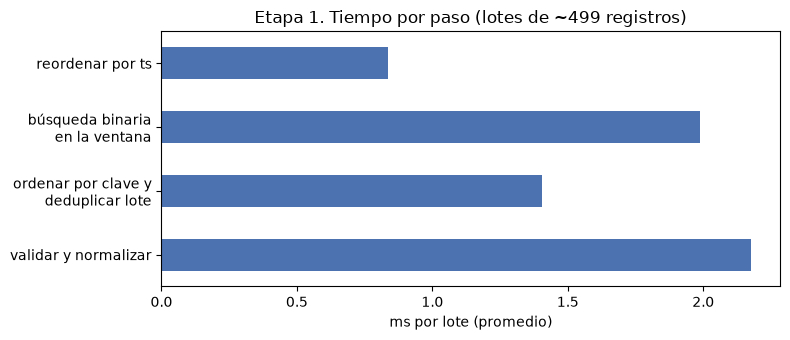

In [14]:
tiempos_pasos = pd.Series(preprocesador.tiempos).rename({
    "validar_normalizar": "validar y normalizar",
    "ordenar_dedup_lote": "ordenar por clave y\ndeduplicar lote",
    "dedup_ventana": "búsqueda binaria\nen la ventana",
    "reordenar_ts": "reordenar por ts",
})
fig, ax = plt.subplots(figsize=(8, 3.5))
(tiempos_pasos * 1000 / m["lotes"]).plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("ms por lote (promedio)")
ax.set_title(f"Etapa 1. Tiempo por paso (lotes de ~{m['entrada'] // m['lotes']} registros)")
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / f"etapa1_tiempo_por_paso_{CATEGORIA}.png", dpi=150)
plt.show()

## Paso 9. Experimentos de complejidad

Se realizan tres experimentos, uno por cada decisión de diseño de la etapa.

| Experimento | Implementación propia | Líneas base | Complejidad esperada |
| --- | --- | --- | --- |
| A. Ordenación | `merge_sort` | `sorted()` (Timsort, en C) | O(n log n) ambos |
| B. Búsqueda en arreglo ordenado | `busqueda_binaria_izq` | `bisect.bisect_left` (en C) y búsqueda lineal | O(log n) frente a O(n) por consulta |
| C. Deduplicación | ordenar con `merge_sort` y recorrer | `set()` (tabla hash) y `sorted()` con recorrido | O(n log n) frente a O(n) esperado |

Condiciones comunes a los tres experimentos.

- **Tamaños.** 1K, 10K, 100K, 1M y 10M.
- **Repeticiones.** 100 para 1K y 10K, 20 para 100K, 5 para 1M y 1 para 10M. A 10M una sola ejecución de `merge_sort` tarda más de un minuto, y con 5 repeticiones a 1M la desviación estándar ya es menor al 5 % de la media.
- **Datos.** Generados con la semilla 42. Los datos de cada tamaño se generan una vez y todas las estructuras reciben los mismos.
- **Recolector de basura.** Desactivado durante cada medición.
- **Resultados.** Se guardan en CSV dentro de `results/`. Si el archivo existe, se lee en lugar de repetir las mediciones. Para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True`.

In [15]:
REEJECUTAR_EXPERIMENTOS = False
TAMANOS = [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
REPETICIONES = {1_000: 100, 10_000: 100, 100_000: 20, 1_000_000: 5, 10_000_000: 1}


def medir(funcion, *args):
    """Tiempo en segundos de funcion(*args) con el recolector de basura desactivado."""
    gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        funcion(*args)
        return time.perf_counter() - t0
    finally:
        gc.enable()


def medir_memoria_pico(funcion, *args):
    """Memoria pico (bytes) asignada durante funcion(*args)."""
    gc.collect()
    tracemalloc.start()
    funcion(*args)
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pico


def ejecutar_experimento(nombre_csv, metodos, generar_datos, repeticiones_para=None):
    """Mide cada método en cada tamaño o lee el CSV si ya existe."""
    ruta = CARPETA_RESULTADOS / nombre_csv
    if ruta.exists() and not REEJECUTAR_EXPERIMENTOS:
        print(f"Resultados leídos de {ruta.relative_to(RAIZ)}")
        return pd.read_csv(ruta)
    filas = []
    for n in TAMANOS:
        datos = generar_datos(n)
        for nombre, (funcion, limite_n) in metodos.items():
            if limite_n is not None and n > limite_n:
                continue
            reps = repeticiones_para(nombre, n) if repeticiones_para else REPETICIONES[n]
            for rep in range(reps):
                filas.append({"metodo": nombre, "n": n, "repeticion": rep, "segundos": medir(funcion, datos)})
        del datos
        print(f"n = {n:>10,} medido")
    resultado = pd.DataFrame(filas)
    resultado.to_csv(ruta, index=False)
    print(f"Resultados guardados en {ruta.relative_to(RAIZ)}")
    return resultado


def resumir(tiempos):
    return (tiempos.groupby(["metodo", "n"])["segundos"]
            .agg(promedio_s="mean", desv_est_s="std", repeticiones="count").reset_index())


def pendientes(resumen, teorico):
    filas = []
    for nombre, datos in resumen.groupby("metodo"):
        k, _ = np.polyfit(np.log10(datos["n"]), np.log10(datos["promedio_s"]), 1)
        filas.append({"metodo": nombre, "pendiente_empirica": round(k, 2), "esperado": teorico[nombre],
                      "rango_n": f"{datos['n'].min():,} a {datos['n'].max():,}"})
    return pd.DataFrame(filas)


def grafica_loglog(resumen, ax, titulo, ylabel="tiempo (s)"):
    for nombre, datos in resumen.groupby("metodo"):
        ax.errorbar(datos["n"], datos["promedio_s"], yerr=datos["desv_est_s"], marker="o", capsize=3, label=nombre)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n"); ax.set_ylabel(ylabel); ax.set_title(titulo)
    ax.legend(fontsize=8)

### Experimento A. Ordenación

Se ordenan n números reales aleatorios. Como n log n crece apenas más rápido que n, en la gráfica log-log ambas curvas tienen pendiente cercana a 1 (entre 1.0 y 1.1). Para distinguir O(n log n) de O(n) se grafica también el tiempo dividido entre n·log₂ n. Si el costo es O(n log n), ese cociente se mantiene aproximadamente constante.

Resultados leídos de results\etapa1_ordenacion_tiempos.csv


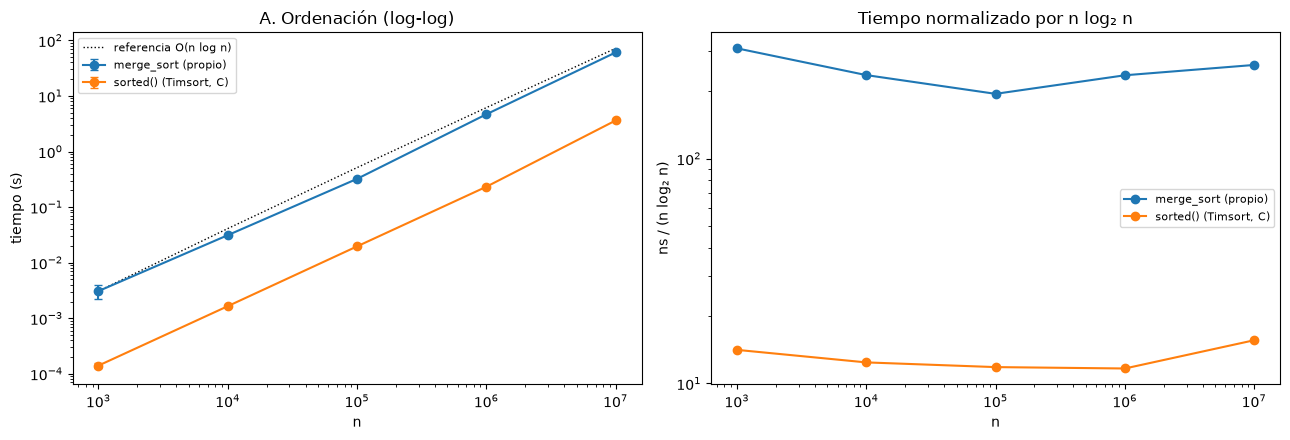

,metodo,n,promedio_s,desv_est_s,repeticiones,ns_por_n_log2n
0,merge_sort (propio),1000,0.003082,0.000903,100,309.232461
1,merge_sort (propio),10000,0.031243,0.001217,100,235.125514
2,merge_sort (propio),100000,0.322343,0.007786,20,194.069779
3,merge_sort (propio),1000000,4.677778,0.185562,5,234.691898
4,merge_sort (propio),10000000,60.657650,NaN,1,260.853887
5,"sorted() (Timsort, C)",1000,0.000141,0.000016,100,14.107269
6,"sorted() (Timsort, C)",10000,0.001649,0.000079,100,12.408381
7,"sorted() (Timsort, C)",100000,0.019642,0.000622,20,11.825599
8,"sorted() (Timsort, C)",1000000,0.232371,0.002257,5,11.658416
9,"sorted() (Timsort, C)",10000000,3.620066,NaN,1,15.567835


,metodo,pendiente_empirica,esperado,rango_n
0,merge_sort (propio),1.08,≈1.0-1.1 (n log n),"1,000 a 10,000,000"
1,"sorted() (Timsort, C)",1.10,≈1.0-1.1 (n log n),"1,000 a 10,000,000"


In [16]:
def generar_reales(n):
    rng = random.Random(SEED)
    return [rng.random() for _ in range(n)]

tiempos_orden = ejecutar_experimento(
    "etapa1_ordenacion_tiempos.csv",
    {"merge_sort (propio)": (merge_sort, None), "sorted() (Timsort, C)": (sorted, None)},
    generar_reales)
resumen_orden = resumir(tiempos_orden)
resumen_orden["ns_por_n_log2n"] = resumen_orden["promedio_s"] / (resumen_orden["n"] * np.log2(resumen_orden["n"])) * 1e9

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
grafica_loglog(resumen_orden, ax1, "A. Ordenación (log-log)")
n_ref = np.array(TAMANOS, dtype=float)
base = resumen_orden.query("metodo == 'merge_sort (propio)'").iloc[0]
ax1.plot(n_ref, base["promedio_s"] * (n_ref * np.log2(n_ref)) / (base["n"] * np.log2(base["n"])),
         "k:", lw=1, label="referencia O(n log n)")
ax1.legend(fontsize=8)
for nombre, datos in resumen_orden.groupby("metodo"):
    ax2.plot(datos["n"], datos["ns_por_n_log2n"], marker="o", label=nombre)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("n"); ax2.set_ylabel("ns / (n log₂ n)"); ax2.set_title("Tiempo normalizado por n log₂ n")
ax2.legend(fontsize=8)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa1_ordenacion.png", dpi=150)
plt.show()

display(resumen_orden)
pendientes(resumen_orden, {"merge_sort (propio)": "≈1.0-1.1 (n log n)", "sorted() (Timsort, C)": "≈1.0-1.1 (n log n)"})

### Experimento B. Búsqueda en un arreglo ordenado

Se busca la posición de 1 000 valores aleatorios en un arreglo ordenado de tamaño n, que representa la ventana de claves. El tiempo reportado es el de las 1 000 consultas.

- La búsqueda binaria debe crecer como log n. Cuando n se multiplica por 10 000, de 1K a 10M, log₂ n solo pasa de 10 a 23.
- La búsqueda lineal debe crecer como n. Se mide solo hasta 100K, con 3 repeticiones en ese tamaño, porque a 10M las 1 000 consultas tardarían varios minutos.

En la gráfica log-log, O(log n) aparece casi plana (pendiente cercana a 0) y O(n) con pendiente cercana a 1.

Resultados leídos de results\etapa1_busqueda_tiempos.csv


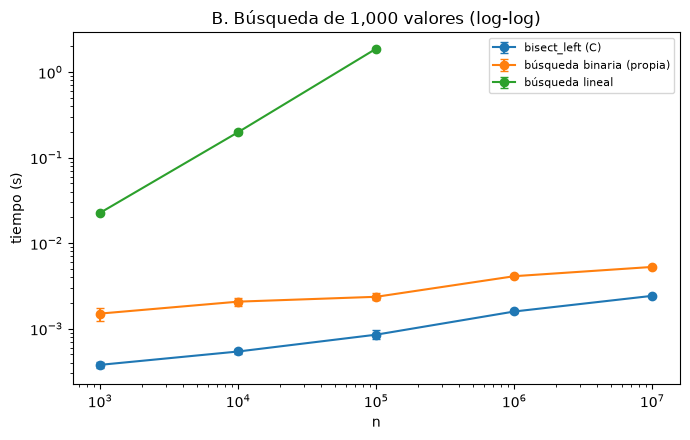

,metodo,n,promedio_s,desv_est_s,repeticiones,us_por_consulta
0,bisect_left (C),1000,0.000378,0.000035,100,0.378074
1,bisect_left (C),10000,0.000542,0.000041,100,0.541593
2,bisect_left (C),100000,0.000852,0.000102,20,0.851980
3,bisect_left (C),1000000,0.001589,0.000071,5,1.589300
4,bisect_left (C),10000000,0.002423,NaN,1,2.423000
5,búsqueda binaria (propia),1000,0.001503,0.000265,100,1.502713
6,búsqueda binaria (propia),10000,0.002072,0.000237,100,2.071642
7,búsqueda binaria (propia),100000,0.002361,0.000221,20,2.360530
8,búsqueda binaria (propia),1000000,0.004110,0.000108,5,4.110200
9,búsqueda binaria (propia),10000000,0.005275,NaN,1,5.275100


,metodo,pendiente_empirica,esperado,rango_n
0,bisect_left (C),0.21,≈0 (log n),"1,000 a 10,000,000"
1,búsqueda binaria (propia),0.14,≈0 (log n),"1,000 a 10,000,000"
2,búsqueda lineal,0.96,≈1 (n),"1,000 a 100,000"


In [17]:
N_CONSULTAS = 1_000

def generar_arreglo_y_consultas(n):
    rng = random.Random(SEED)
    arreglo = list(range(0, 2 * n, 2))                       # n valores pares ordenados
    consultas = [rng.randrange(0, 2 * n) for _ in range(N_CONSULTAS)]
    return arreglo, consultas

def busqueda_lineal_izq(arreglo, x):
    """Primera posición i con arreglo[i] >= x, revisando uno por uno. O(n)."""
    for i, valor in enumerate(arreglo):
        if valor >= x:
            return i
    return len(arreglo)

def consultas_binaria(datos):
    arreglo, consultas = datos
    for x in consultas:
        busqueda_binaria_izq(arreglo, x)

def consultas_bisect(datos):
    arreglo, consultas = datos
    for x in consultas:
        bisect.bisect_left(arreglo, x)

def consultas_lineal(datos):
    arreglo, consultas = datos
    for x in consultas:
        busqueda_lineal_izq(arreglo, x)

tiempos_busqueda = ejecutar_experimento(
    "etapa1_busqueda_tiempos.csv",
    {"búsqueda binaria (propia)": (consultas_binaria, None),
     "bisect_left (C)": (consultas_bisect, None),
     "búsqueda lineal": (consultas_lineal, 100_000)},
    generar_arreglo_y_consultas,
    repeticiones_para=lambda nombre, n: min(REPETICIONES[n], 3) if nombre == "búsqueda lineal" and n >= 100_000 else REPETICIONES[n])
resumen_busqueda = resumir(tiempos_busqueda)
resumen_busqueda["us_por_consulta"] = resumen_busqueda["promedio_s"] / N_CONSULTAS * 1e6

fig, ax = plt.subplots(figsize=(7, 4.5))
grafica_loglog(resumen_busqueda, ax, f"B. Búsqueda de {N_CONSULTAS:,} valores (log-log)")
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa1_busqueda.png", dpi=150)
plt.show()

display(resumen_busqueda)
pendientes(resumen_busqueda, {"búsqueda binaria (propia)": "≈0 (log n)", "bisect_left (C)": "≈0 (log n)",
                              "búsqueda lineal": "≈1 (n)"})

### Experimento C. Deduplicación

Se eliminan los duplicados de una lista de n claves enteras, donde el 5 % son repeticiones, una proporción parecida a la que inyecta la etapa 0. Se comparan tres métodos.

- **merge_sort y recorrido.** Es el método de la etapa 1, en O(n log n).
- **sorted() y recorrido.** Es el mismo algoritmo pero con la ordenación en C. Separa el efecto del algoritmo del efecto del lenguaje.
- **set().** Recorre la lista y conserva cada clave que no estaba en el conjunto. Cuesta O(n) en promedio, porque cada consulta a la tabla hash es O(1) esperado.

Se mide también la memoria pico con `tracemalloc`, hasta 1M por el costo de la medición.

Este experimento compara solo claves exactas. En el pipeline real la etapa usa ordenar y recorrer porque admite la tolerancia de tiempo del paso 5, cosa que un `set()` no puede hacer.

Resultados leídos de results\etapa1_dedup_tiempos.csv


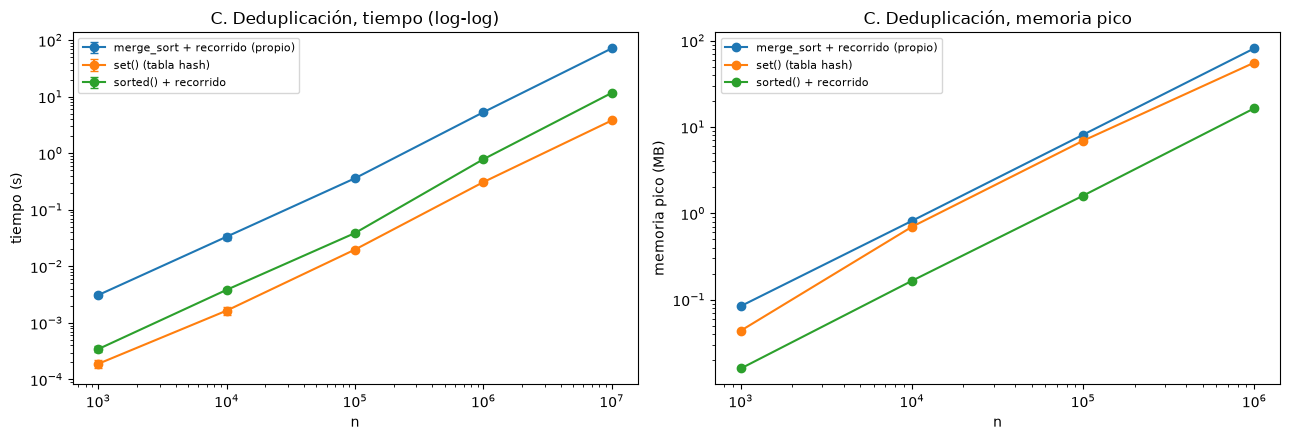

,metodo,n,promedio_s,desv_est_s,repeticiones
0,merge_sort + recorrido (propio),1000,0.003113,0.000261,100
1,merge_sort + recorrido (propio),10000,0.033489,0.003650,100
2,merge_sort + recorrido (propio),100000,0.361663,0.014420,20
3,merge_sort + recorrido (propio),1000000,5.319778,0.028530,5
4,merge_sort + recorrido (propio),10000000,71.575874,NaN,1
5,set() (tabla hash),1000,0.000189,0.000033,100
6,set() (tabla hash),10000,0.001652,0.000276,100
7,set() (tabla hash),100000,0.019844,0.000935,20
8,set() (tabla hash),1000000,0.309241,0.006615,5
9,set() (tabla hash),10000000,3.805611,NaN,1


metodo,merge_sort + recorrido (propio),set() (tabla hash),sorted() + recorrido
n,,,
1000,0.08,0.04,0.02
10000,0.82,0.70,0.17
100000,8.13,6.92,1.60
1000000,81.35,55.61,16.45


,metodo,pendiente_empirica,esperado,rango_n
0,merge_sort + recorrido (propio),1.09,≈1.0-1.1 (n log n),"1,000 a 10,000,000"
1,set() (tabla hash),1.09,≈1 (n),"1,000 a 10,000,000"
2,sorted() + recorrido,1.14,≈1.0-1.1 (n log n),"1,000 a 10,000,000"


In [18]:
def generar_claves_con_duplicados(n, proporcion_dup=0.05):
    rng = random.Random(SEED)
    n_unicas = int(n * (1 - proporcion_dup))
    claves = [rng.getrandbits(48) for _ in range(n_unicas)]
    claves += [rng.choice(claves) for _ in range(n - n_unicas)]   # repeticiones
    rng.shuffle(claves)
    return claves

def recorrer_y_quitar_adyacentes(ordenadas):
    unicas = []
    for k in ordenadas:
        if not unicas or k != unicas[-1]:
            unicas.append(k)
    return unicas

def dedup_merge_sort(claves):
    return recorrer_y_quitar_adyacentes(merge_sort(claves))

def dedup_sorted(claves):
    return recorrer_y_quitar_adyacentes(sorted(claves))

def dedup_set(claves):
    vistas = set()
    unicas = []
    for k in claves:
        if k not in vistas:
            vistas.add(k)
            unicas.append(k)
    return unicas

# Los tres métodos deben encontrar las mismas claves únicas
muestra = generar_claves_con_duplicados(10_000)
assert dedup_merge_sort(muestra) == dedup_sorted(muestra) == sorted(dedup_set(muestra))

METODOS_DEDUP = {"merge_sort + recorrido (propio)": (dedup_merge_sort, None),
                 "sorted() + recorrido": (dedup_sorted, None),
                 "set() (tabla hash)": (dedup_set, None)}
tiempos_dedup = ejecutar_experimento("etapa1_dedup_tiempos.csv", METODOS_DEDUP, generar_claves_con_duplicados)
resumen_dedup = resumir(tiempos_dedup)

ruta_memoria = CARPETA_RESULTADOS / "etapa1_dedup_memoria.csv"
if ruta_memoria.exists() and not REEJECUTAR_EXPERIMENTOS:
    memoria_dedup = pd.read_csv(ruta_memoria)
else:
    filas = []
    for n in [1_000, 10_000, 100_000, 1_000_000]:
        claves = generar_claves_con_duplicados(n)
        for nombre, (funcion, _) in METODOS_DEDUP.items():
            filas.append({"metodo": nombre, "n": n, "pico_mb": medir_memoria_pico(funcion, claves) / 1e6})
    memoria_dedup = pd.DataFrame(filas)
    memoria_dedup.to_csv(ruta_memoria, index=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
grafica_loglog(resumen_dedup, ax1, "C. Deduplicación, tiempo (log-log)")
for nombre, datos in memoria_dedup.groupby("metodo"):
    ax2.plot(datos["n"], datos["pico_mb"], marker="o", label=nombre)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("n"); ax2.set_ylabel("memoria pico (MB)"); ax2.set_title("C. Deduplicación, memoria pico")
ax2.legend(fontsize=8)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa1_dedup.png", dpi=150)
plt.show()

display(resumen_dedup)
display(memoria_dedup.pivot(index="n", columns="metodo", values="pico_mb").round(2))
pendientes(resumen_dedup, {"merge_sort + recorrido (propio)": "≈1.0-1.1 (n log n)",
                           "sorted() + recorrido": "≈1.0-1.1 (n log n)", "set() (tabla hash)": "≈1 (n)"})

### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada en `results/`. Al medir de nuevo pueden variar ligeramente.

- **Ordenación.** `merge_sort` y `sorted()` tienen pendientes de 1.08 y 1.10, y el tiempo de `merge_sort` dividido entre n log₂ n se mantiene entre unos 190 y 310 ns de 1K a 10M. Esto es coherente con O(n log n). `sorted()` es unas 17 a 22 veces más rápida porque Timsort está escrito en C. La diferencia es un factor constante.
- **Búsqueda.** De 1K a 10M, n crece 10 000 veces y la búsqueda binaria propia solo pasa de unos 1.5 a 5.3 µs por consulta, con pendiente 0.14. Esto corresponde a O(log n). La búsqueda lineal tiene pendiente 0.96, que corresponde a O(n), y a 100K ya tarda unos 1 900 µs por consulta, unas 800 veces más que la búsqueda binaria.
- **Deduplicación, tiempo.** `set()` es el método más rápido, como predice su costo O(n) esperado. Su pendiente es 1.09 y no 1 porque con tablas hash grandes empeora el uso de la caché del procesador. Ordenar y recorrer con `merge_sort` es unas 17 veces más lento, por el factor log n y porque está escrito en Python.
- **Deduplicación, memoria.** `sorted()` con recorrido es el método más económico (unos 16 bytes por elemento a 1M), porque solo crea la lista ordenada y la de únicos. `set()` usa unos 56 bytes por elemento por la tabla hash. `merge_sort` usa unos 81 bytes por elemento, porque crea pares (clave, elemento) y listas temporales en cada mezcla.

En la etapa 1 el factor log n es pequeño porque cada lote tiene unos 500 eventos (log₂ 500 ≈ 9). A cambio de ese costo, ordenar y recorrer admite la tolerancia de tiempo, deja el lote listo para la mezcla con la ventana y no depende de una función hash.

## Paso 10. Salida de la etapa 1 para la etapa 2

Los lotes limpios se guardan en `data/interim/<CATEGORIA>/`. El notebook de la etapa 2 los leerá lote por lote para asignar prioridades.

| Archivo | Contenido | Lo usa |
| --- | --- | --- |
| `etapa1_lotes.jsonl` | Una línea por lote con sus eventos limpios en el formato `Event` | Etapa 2 |
| `etapa1_rechazados.jsonl` | Una línea por registro rechazado con su motivo | Auditoría |
| `etapa1_metricas.json` | Conteos de entrada, salida, rechazos y duplicados | Informe |

In [19]:
ruta_salida = CARPETA_INTERIM / "etapa1_lotes.jsonl"
with open(ruta_salida, "w", encoding="utf-8") as archivo:
    for numero, lote in lotes_limpios:
        archivo.write(json.dumps({"lote": numero, "eventos": [asdict(e) for e in lote]}) + "\n")

ruta_rechazados = CARPETA_INTERIM / "etapa1_rechazados.jsonl"
with open(ruta_rechazados, "w", encoding="utf-8") as archivo:
    nodo = preprocesador.rechazados._cabeza
    while nodo is not None:
        motivo, registro = nodo.valor
        archivo.write(json.dumps({"motivo": motivo, "registro": registro}) + "\n")
        nodo = nodo.siguiente

metricas_salida = {**dict(preprocesador.metricas), "rechazos_por_motivo": dict(preprocesador.motivos),
                   "segundos_por_paso": dict(preprocesador.tiempos),
                   "ventana_s": VENTANA_S, "tolerancia_s": TOLERANCIA_S, "semilla": SEED}
(CARPETA_INTERIM / "etapa1_metricas.json").write_text(json.dumps(metricas_salida, indent=2), encoding="utf-8")

# Verificación: se relee la salida y se reconstruyen los eventos
total = 0
with open(ruta_salida, encoding="utf-8") as archivo:
    for linea in archivo:
        eventos = [Event(**d) for d in json.loads(linea)["eventos"]]
        total += len(eventos)
assert total == preprocesador.metricas["salida"]
print(f"{ruta_salida.relative_to(RAIZ)}: {total:,} eventos en {len(lotes_limpios)} lotes "
      f"({ruta_salida.stat().st_size / 1e6:.1f} MB)")
print(f"{ruta_rechazados.relative_to(RAIZ)}: {len(preprocesador.rechazados):,} registros rechazados")

data\interim\All_Beauty\etapa1_lotes.jsonl: 127,170 eventos en 269 lotes (44.1 MB)
data\interim\All_Beauty\etapa1_rechazados.jsonl: 1,291 registros rechazados


## Resumen de la etapa 1

| Aspecto | Decisión |
| --- | --- |
| Validación | Reglas por campo y por tipo de evento; los inválidos van a una `ColaEnlazada` de rechazados con su motivo |
| Normalización | `ts` de ms a s, precio a `float`, `user_id` y `parent_asin` en mayúsculas, categoría canónica, búsqueda en minúsculas |
| Ordenación | `merge_sort` propio, O(n log n) garantizado y estable |
| Duplicados en el lote | Ordenar por (clave, ts) y recorrer, con tolerancia de 1 s, en O(b log b) |
| Duplicados entre lotes | Ventana ordenada de 10 minutos con búsqueda binaria propia, O(log w) por evento y O(w + b) de actualización por lote |
| Orden temporal | Reordenación por `ts` dentro de cada lote; el desorden entre lotes queda acotado a los eventos que llegan más tarde que su lote |
| Salida | Lotes de `Event` en `data/interim/<CATEGORIA>/etapa1_lotes.jsonl` |

Referencias. Cormen, T. H., Leiserson, C. E., Rivest, R. L., y Stein, C. (2022). *Introduction to Algorithms* (4.ª ed.), cap. 2. Bloom, B. H. (1970). Space/time trade-offs in hash coding with allowable errors. *Communications of the ACM*, 13(7), 422-426.